In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Load data
df = pd.read_csv('/Users/macbook/Downloads/indonesia-financial-timeseries/data/clean_data.csv', parse_dates=['Date'], index_col='Date')

# Feature Engineering
df['IHSG_ret'] = df['IHSG'].pct_change()
df['USDIDR_ret'] = df['USDIDR'].pct_change()
df['OIL_ret'] = df['OIL'].pct_change()
df['VIX_lag1'] = df['VIX'].shift(1)
df['VIX_lag2'] = df['VIX'].shift(2)
df['USDIDR_ret_lag1'] = df['USDIDR_ret'].shift(1)
df['Target'] = np.where(df['IHSG_ret'].shift(-1) > 0, 1, 0)

df_model = df.dropna(subset=['VIX_lag2', 'USDIDR_ret_lag1', 'Target']).copy()

features = ['VIX_lag1', 'VIX_lag2', 'USDIDR_ret_lag1', 'IHSG_ret', 'OIL_ret']
X = df_model[features]
y = df_model['Target']

# Split Data (80% Train, 20% Test)
split_index = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Latih XGBoost
model = xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

print(f"Model siap dievaluasi untuk periode {X_test.index.min().date()} s/d {X_test.index.max().date()}")

Model siap dievaluasi untuk periode 2023-02-14 s/d 2026-05-29


=== HASIL SIMULASI INVESTASI ===
Total Return Buy & Hold : -11.20%
Total Return Model AI   : -44.32%


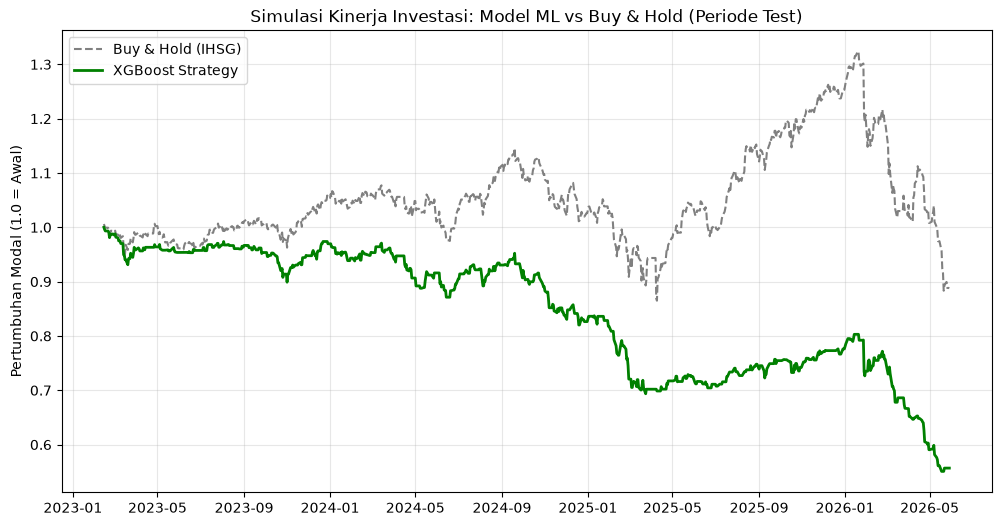

In [2]:
# Mengambil return IHSG pada periode test
returns = df_model.loc[X_test.index, 'IHSG_ret']

# Strategi 1: Buy & Hold
cum_buy_hold = (1 + returns).cumprod()

# Strategi 2: Model AI (Jika prediksi 1/Naik, pegang IHSG. Jika 0/Turun, pegang uang tunai/0%)
y_prob = model.predict_proba(X_test)[:, 1]
strategy_returns = returns * (y_prob > 0.5) # 1 jika naik, 0 jika turun
cum_strategy = (1 + strategy_returns).cumprod()

# Hitung Total Return
ret_bh = (cum_buy_hold.iloc[-1] - 1) * 100
ret_model = (cum_strategy.iloc[-1] - 1) * 100

print("=== HASIL SIMULASI INVESTASI ===")
print(f"Total Return Buy & Hold : {ret_bh:.2f}%")
print(f"Total Return Model AI   : {ret_model:.2f}%")

# Visualisasi
plt.figure(figsize=(12, 6))
plt.plot(cum_buy_hold.index, cum_buy_hold, label='Buy & Hold (IHSG)', color='gray', linestyle='--')
plt.plot(cum_strategy.index, cum_strategy, label='XGBoost Strategy', color='green', linewidth=2)
plt.title('Simulasi Kinerja Investasi: Model ML vs Buy & Hold (Periode Test)')
plt.ylabel('Pertumbuhan Modal (1.0 = Awal)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [3]:
def calculate_max_drawdown(cumulative_returns):
    running_max = cumulative_returns.cummax()
    drawdown = (cumulative_returns - running_max) / running_max
    return drawdown.min() * 100

mdd_bh = calculate_max_drawdown(cum_buy_hold)
mdd_model = calculate_max_drawdown(cum_strategy)

print("=== ANALISIS RISIKO ===")
print(f"Max Drawdown Buy & Hold : {mdd_bh:.2f}%")
print(f"Max Drawdown Model AI   : {mdd_model:.2f}%")

if mdd_model > mdd_bh:
    print("Kesimpulan: Model AI berhasil MEMITIGASI RISIKO (kerugian lebih kecil saat pasar jatuh).")
else:
    print("Kesimpulan: Model AI memiliki risiko penurunan yang lebih besar.")

=== ANALISIS RISIKO ===
Max Drawdown Buy & Hold : -33.28%
Max Drawdown Model AI   : -44.93%
Kesimpulan: Model AI memiliki risiko penurunan yang lebih besar.


In [4]:
# 1. Hitung Win Rate
# Kita hanya melihat hari-hari di mana model memprediksi "Naik" (probabilitas > 0.5)
# dan kita benar-benar masuk pasar.
trades = strategy_returns[strategy_returns != 0] 
win_rate = (trades > 0).mean() * 100

print("=== METRIK TRADING ===")
print(f"Win Rate (Persentase Profit): {win_rate:.2f}%")

# 2. Hitung Sharpe Ratio (Asumsi risk-free rate = 0)
# Kita kalikan dengan akar 252 karena ada 252 hari bursa dalam setahun (annualized)
sharpe_model = (np.mean(strategy_returns) / np.std(strategy_returns)) * np.sqrt(252)
sharpe_bh = (np.mean(returns) / np.std(returns)) * np.sqrt(252)

print(f"\n=== RISK-ADJUSTED RETURN (SHARPE RATIO) ===")
print(f"Sharpe Ratio Buy & Hold : {sharpe_bh:.2f}")
print(f"Sharpe Ratio Model AI   : {sharpe_model:.2f}")

if sharpe_model > sharpe_bh:
    print("Kesimpulan: Model AI memberikan return yang lebih efisien (risiko lebih kecil untuk keuntungan yang sama).")
else:
    print("Kesimpulan: Buy & Hold masih lebih efisien secara risiko.")

=== METRIK TRADING ===
Win Rate (Persentase Profit): 47.67%

=== RISK-ADJUSTED RETURN (SHARPE RATIO) ===
Sharpe Ratio Buy & Hold : -0.13
Sharpe Ratio Model AI   : -1.39
Kesimpulan: Buy & Hold masih lebih efisien secara risiko.
